### 1. Import tools for reading and plotting
These tools handle paths, photos, tables and charts.

In [1]:
import os
import random
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
print("Image, table and plotting tools are ready.")

Image, table and plotting tools are ready.


### 2. Import machine-learning tools
PyTorch trains the model; scikit-learn helps split the data and measure performance.

In [2]:
import copy
import json
import time
import io
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
print("PyTorch:", torch.__version__)

PyTorch: 2.14.1+cpu


### 3. Choose reproducible settings
A fixed seed makes the split repeatable. The output order of the four classes stays fixed.

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASS_NAMES = ["cordana", "healthy", "pestalotiopsis", "sigatoka"]
CLASS_TO_NUMBER = {name: number for number, name in enumerate(CLASS_NAMES)}
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE)
print("Class numbers:", CLASS_TO_NUMBER)
print("Output folder:", OUTPUT_DIR.resolve())

Device: cpu
Class numbers: {'cordana': 0, 'healthy': 1, 'pestalotiopsis': 2, 'sigatoka': 3}
Output folder: F:\janv\output


### 4. Find the dataset
Search only OriginalSet, or use BANANA_DATASET_PATH if you specify a folder.

In [4]:
custom_folder = os.environ.get("BANANA_DATASET_PATH")
if custom_folder:
    dataset_folder = Path(custom_folder)
else:
    search_roots = [Path("data"), Path("/kaggle/input")]
    matches = [folder for root in search_roots if root.exists()
               for folder in root.rglob("OriginalSet") if folder.is_dir()]
    if len(matches) != 1:
        raise FileNotFoundError("Set BANANA_DATASET_PATH to the intended OriginalSet folder.")
    dataset_folder = matches[0]
assert dataset_folder.is_dir(), "Dataset folder not found."
print("Reading:", dataset_folder.resolve())

Reading: F:\janv\data\OriginalSet


### 5. Define an image check
Hash decoded RGB pixels to find identical images even when filenames differ.

In [5]:
def inspect_image(image_path, class_name):
    with Image.open(image_path) as image:
        image = image.convert("RGB")
        signature = str(image.size).encode() + image.tobytes()
        image_hash = hashlib.sha256(signature).hexdigest()
        width, height = image.size
    return {"image_path": str(image_path), "image_id": image_path.relative_to(dataset_folder).as_posix(),
            "class_name": class_name, "class_number": CLASS_TO_NUMBER[class_name],
            "image_hash": image_hash, "width": width, "height": height}
print("Image-checking function ready.")

Image-checking function ready.


### 6. Read images and labels
Each folder supplies the class label. Unreadable images are reported instead of silently ignored.

In [6]:
image_records, unreadable_images = [], []
for class_name in CLASS_NAMES:
    class_folder = dataset_folder / class_name
    assert class_folder.is_dir(), f"Missing class folder: {class_folder}"
    for image_path in sorted(class_folder.rglob("*")):
        if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
            continue
        try:
            image_records.append(inspect_image(image_path, class_name))
        except (OSError, ValueError) as error:
            unreadable_images.append((str(image_path), str(error)))
raw_images = pd.DataFrame(image_records)
assert len(raw_images) > 0, "No readable images found."
print("Readable source images:", len(raw_images))
print("Unreadable images:", len(unreadable_images))
if unreadable_images:
    display(pd.DataFrame(unreadable_images, columns=["image", "problem"]))

C:\Users\Godson IT\AppData\Local\Programs\Python\Python312\Lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))
C:\Users\Godson IT\AppData\Local\Programs\Python\Python312\Lib\site-packages\PIL\JpegImagePlugin.py:880: UserWarning: Image appears to be a malformed MPO file, it will be interpreted as a base JPEG file
  warnings.warn(


Readable source images: 937
Unreadable images: 0


### 7. Remove contradictory labels and duplicate copies
Exclude identical-image groups with conflicting labels, then keep one copy of each remaining image before splitting.

In [7]:
labels_per_hash = raw_images.groupby("image_hash").class_name.nunique()
ambiguous_hashes = labels_per_hash[labels_per_hash > 1].index
ambiguous_images = raw_images[raw_images.image_hash.isin(ambiguous_hashes)]
consistent_images = raw_images[~raw_images.image_hash.isin(ambiguous_hashes)]
images = consistent_images.drop_duplicates("image_hash").reset_index(drop=True)
print("Conflicting-label images excluded:", len(ambiguous_images))
print("Duplicate copies removed:", len(consistent_images) - len(images))
print("Unique images retained:", len(images))
display(ambiguous_images[["image_id", "class_name"]])
display(images[["image_id", "class_name", "width", "height"]].head())

Conflicting-label images excluded: 2
Duplicate copies removed: 38
Unique images retained: 897


,image_id,class_name
189,healthy/122.jpeg,healthy
440,pestalotiopsis/78.jpeg,pestalotiopsis


,image_id,class_name,width,height
0,cordana/0.jpeg,cordana,224,224
1,cordana/1.jpeg,cordana,224,224
2,cordana/10.jpeg,cordana,224,224
3,cordana/100.jpeg,cordana,224,224
4,cordana/101.jpeg,cordana,224,224


### 8. Count and discuss the classes
A large majority class can make accuracy misleading. Class weights help training; macro F1 treats the four classes equally.

In [8]:
class_counts = images.class_name.value_counts().reindex(CLASS_NAMES)
class_summary = pd.DataFrame({"images": class_counts})
class_summary["percentage"] = (100 * class_counts / len(images)).round(2)
display(class_summary)
print(f"Largest-to-smallest class ratio: {class_counts.max() / class_counts.min():.2f}:1")
print("Class weights will help training; macro F1 will also be reported.")

,images,percentage
class_name,,
cordana,162,18.06
healthy,90,10.03
pestalotiopsis,172,19.18
sigatoka,473,52.73


Largest-to-smallest class ratio: 5.26:1
Class weights will help training; macro F1 will also be reported.


### 9. Visualize class balance
Bar heights show the number of unique images in each class.

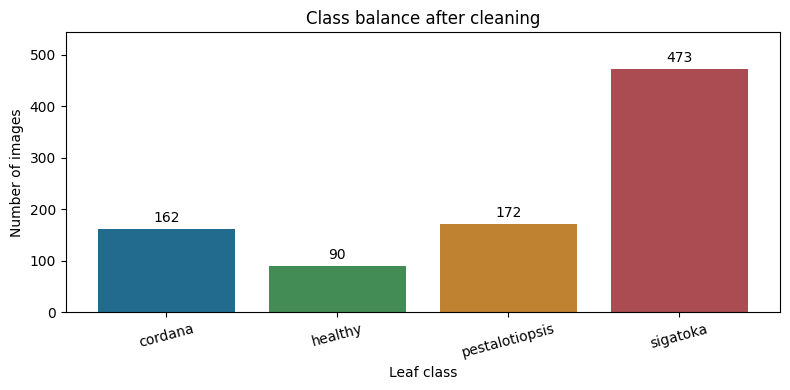

In [9]:
figure, axis = plt.subplots(figsize=(8, 4))
bars = axis.bar(CLASS_NAMES, class_counts, color=["#236b8e", "#438c56", "#bf8230", "#aa4c52"])
axis.bar_label(bars, padding=3)
axis.set(title="Class balance after cleaning", xlabel="Leaf class", ylabel="Number of images")
axis.set_ylim(0, class_counts.max() * 1.15)
axis.tick_params(axis="x", rotation=15)
figure.tight_layout()
plt.show()

### 10. Display labeled samples
Three examples from every class confirm that paths, labels and image reading are correct.

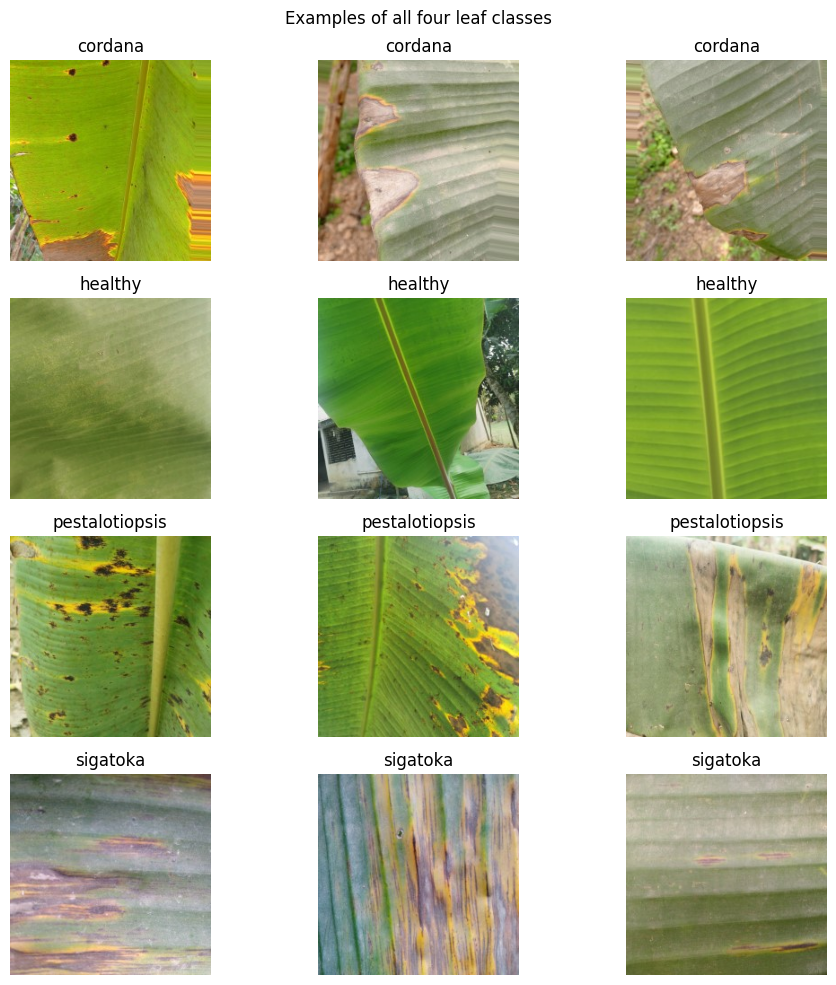

In [10]:
figure, axes = plt.subplots(4, 3, figsize=(10, 10))
for row, class_name in enumerate(CLASS_NAMES):
    samples = images[images.class_name == class_name].sample(3, random_state=SEED)
    for axis, image_path in zip(axes[row], samples.image_path):
        with Image.open(image_path) as image:
            axis.imshow(image.convert("RGB"))
        axis.set_title(class_name)
        axis.axis("off")
figure.suptitle("Examples of all four leaf classes")
figure.tight_layout()
plt.show()

### 11. Make a stratified split
Stratification preserves class proportions approximately. Do not recreate this split later.

In [11]:
train_images, remaining_images = train_test_split(
    images, test_size=0.30, stratify=images.class_name, random_state=SEED)
validation_images, test_images = train_test_split(
    remaining_images, test_size=0.50, stratify=remaining_images.class_name, random_state=SEED)
train_images = train_images.reset_index(drop=True)
validation_images = validation_images.reset_index(drop=True)
test_images = test_images.reset_index(drop=True)
print("Fixed training, validation and test tables ready.")

Fixed training, validation and test tables ready.


### 12. Check for leakage
No path or identical RGB content may cross splits. These checks cannot detect different photos of the same plant.

In [12]:
for column in ["image_path", "image_hash"]:
    training = set(train_images[column])
    validation = set(validation_images[column])
    testing = set(test_images[column])
    assert training.isdisjoint(validation)
    assert training.isdisjoint(testing)
    assert validation.isdisjoint(testing)
assert len(train_images) + len(validation_images) + len(test_images) == len(images)
print("Passed: paths and image hashes are separate between splits.")

Passed: paths and image hashes are separate between splits.


### 13. Report and visualize split sizes
The table shows exact counts and percentages; the chart compares split sizes.

,split,images,percentage
0,Training,627,69.90
1,Validation,135,15.05
2,Test,135,15.05


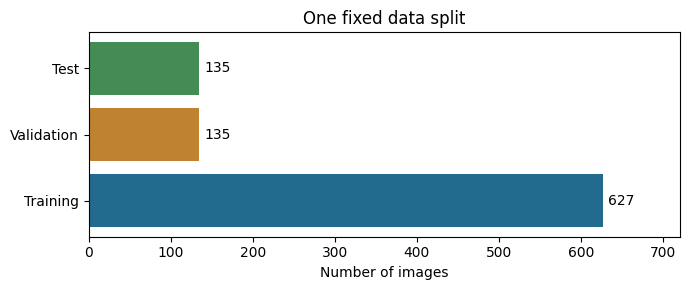

In [13]:
split_sizes = pd.DataFrame({"split": ["Training", "Validation", "Test"],
    "images": [len(train_images), len(validation_images), len(test_images)]})
split_sizes["percentage"] = (100 * split_sizes.images / len(images)).round(2)
display(split_sizes)
figure, axis = plt.subplots(figsize=(7, 3))
bars = axis.barh(split_sizes["split"], split_sizes.images, color=["#236b8e", "#bf8230", "#438c56"])
axis.bar_label(bars, padding=4)
axis.set(xlabel="Number of images", title="One fixed data split", xlim=(0, len(train_images) * 1.15))
figure.tight_layout()
plt.show()

### 14. Save the split record
Save which image belongs to each split, and check that all four classes occur in every split.

In [14]:
split_tables = {"training": train_images, "validation": validation_images, "test": test_images}
display(pd.DataFrame({name: table.class_name.value_counts().reindex(CLASS_NAMES)
                      for name, table in split_tables.items()}))
manifest = pd.concat([table.assign(split=name) for name, table in split_tables.items()])
manifest[["image_id", "class_name", "image_hash", "split"]].to_csv(
    OUTPUT_DIR / "split_manifest.csv", index=False)
print("Saved:", OUTPUT_DIR / "split_manifest.csv")

,training,validation,test
class_name,,,
cordana,113,24,25
healthy,63,14,13
pestalotiopsis,120,26,26
sigatoka,331,71,71


Saved: output\split_manifest.csv


### 15. Define deterministic preprocessing
Validation, test and uploaded photos use identical resize, crop and normalization.

In [15]:
IMAGE_MEAN = [0.485, 0.456, 0.406]
IMAGE_STD = [0.229, 0.224, 0.225]
resize_and_crop = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])
evaluation_transform = transforms.Compose([
    resize_and_crop, transforms.ToTensor(), transforms.Normalize(IMAGE_MEAN, IMAGE_STD)
])
print("RGB -> resize -> 224 x 224 crop -> tensor -> ImageNet normalization.")

RGB -> resize -> 224 x 224 crop -> tensor -> ImageNet normalization.


### 16. Inspect pixel preparation
Standardized values can be negative; use the RGB version for displaying the photo.

In [16]:
with Image.open(train_images.iloc[0].image_path) as image:
    example_image = image.convert("RGB")
resized_example = resize_and_crop(example_image)
unit_pixels = transforms.ToTensor()(resized_example)
normalized_pixels = evaluation_transform(example_image)
print("Original size:", example_image.size)
print("Resized/cropped size:", resized_example.size)
print("Tensor shape (channels, height, width):", tuple(normalized_pixels.shape))
print(f"After division by 255: {unit_pixels.min():.3f} to {unit_pixels.max():.3f}")
print(f"After channel normalization: {normalized_pixels.min():.3f} to {normalized_pixels.max():.3f}")

Original size: (224, 224)
Resized/cropped size: (224, 224)
Tensor shape (channels, height, width): (3, 224, 224)


After division by 255: 0.000 to 1.000
After channel normalization: -1.804 to 2.376


### 17. Compare the original and model view
Consistent dimensions help batching, but cropping may remove information near image edges.

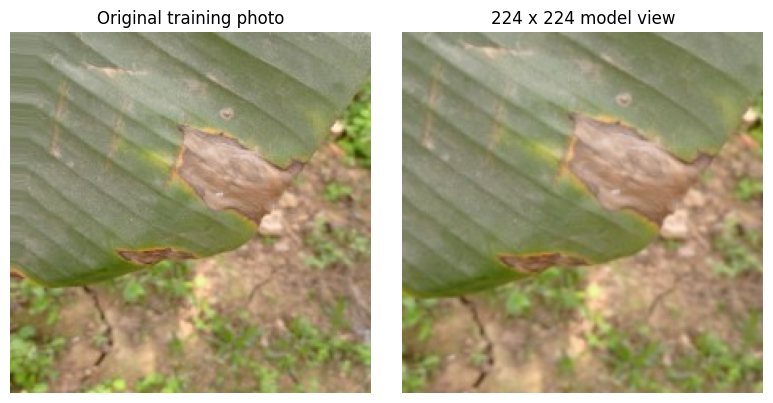

In [17]:
figure, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(example_image)
axes[0].set_title("Original training photo")
axes[1].imshow(resized_example)
axes[1].set_title("224 x 224 model view")
for axis in axes:
    axis.axis("off")
figure.tight_layout()
plt.show()

### 18. Define training-only augmentation
Small rotations, flips and mild color changes expose realistic variation. Validation and test remain deterministic.

In [18]:
training_transform = transforms.Compose([
    resize_and_crop,
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.05),
    transforms.ToTensor(), transforms.Normalize(IMAGE_MEAN, IMAGE_STD)
])
print("Training: horizontal flip, rotation up to 15 degrees and mild color variation.")
print("Validation and test: no augmentation.")

Training: horizontal flip, rotation up to 15 degrees and mild color variation.
Validation and test: no augmentation.


### 19. Preview augmented training images
Undo normalization only to display the colors correctly.

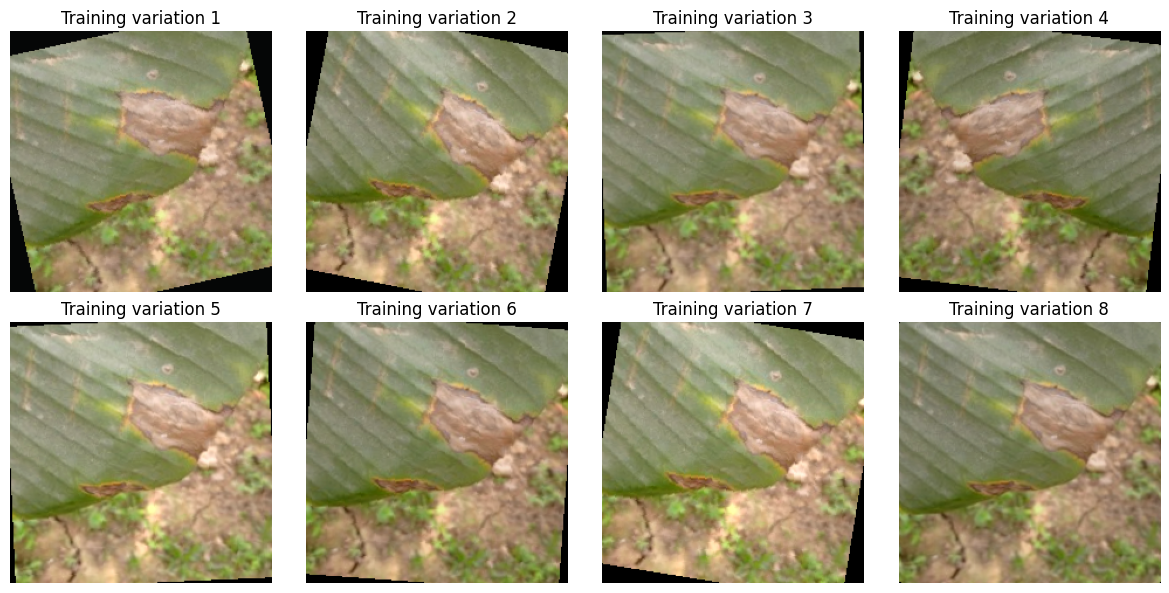

In [19]:
figure, axes = plt.subplots(2, 4, figsize=(12, 6))
for number, axis in enumerate(axes.flat):
    tensor = training_transform(example_image)
    pixels = tensor.permute(1, 2, 0).numpy() * np.array(IMAGE_STD) + np.array(IMAGE_MEAN)
    axis.imshow(np.clip(pixels, 0, 1))
    axis.set_title(f"Training variation {number + 1}")
    axis.axis("off")
figure.tight_layout()
plt.show()

### 20. Define the image dataset
Each item returns one processed photo and its numeric label.

In [20]:
class LeafDataset(Dataset):
    def __init__(self, image_table, transform):
        self.image_table = image_table.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.image_table)

    def __getitem__(self, index):
        row = self.image_table.iloc[index]
        with Image.open(row.image_path) as image:
            photo = image.convert("RGB")
        return self.transform(photo), int(row.class_number)

print("LeafDataset is ready to load matched image-label pairs.")

LeafDataset is ready to load matched image-label pairs.


### 21. Create training and validation batches
Shuffle training only. num_workers=0 works inside Windows notebooks. Build the test loader only for final evaluation.

In [21]:
BATCH_SIZE = 32
train_loader = DataLoader(LeafDataset(train_images, training_transform),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
validation_loader = DataLoader(LeafDataset(validation_images, evaluation_transform),
                               batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
train_check_loader = DataLoader(LeafDataset(train_images, evaluation_transform),
                                batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Deterministic training loader ready for the final fit comparison.")

Training batches: 20
Validation batches: 5
Deterministic training loader ready for the final fit comparison.


### 22. Load the pretrained model
The first run downloads official weights. Replace the original final classifier with four outputs.

In [22]:
pretrained_weights = models.MobileNet_V3_Small_Weights.DEFAULT
model = models.mobilenet_v3_small(weights=pretrained_weights)
input_features = model.classifier[-1].in_features
model.classifier[-1] = nn.Linear(input_features, len(CLASS_NAMES))
print("Model: MobileNetV3 Small with ImageNet features.")
print("Final layer:", model.classifier[-1])

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to C:\Users\Godson IT/.cache\torch\hub\checkpoints\mobilenet_v3_small-047dcff4.pth



  0%|          | 0.00/9.83M [00:00<?, ?B/s]


  1%|▏         | 128k/9.83M [00:00<00:26, 385kB/s]


  3%|▎         | 256k/9.83M [00:00<00:19, 509kB/s]


  4%|▍         | 384k/9.83M [00:00<00:17, 553kB/s]

...


 97%|█████████▋| 9.50M/9.83M [00:24<00:00, 397kB/s]


 98%|█████████▊| 9.62M/9.83M [00:25<00:00, 490kB/s]


 99%|█████████▉| 9.75M/9.83M [00:25<00:00, 380kB/s]


100%|██████████| 9.83M/9.83M [00:25<00:00, 402kB/s]

Model: MobileNetV3 Small with ImageNet features.
Final layer: Linear(in_features=1024, out_features=4, bias=True)


### 23. Choose which layers can learn
Keep early features fixed. Train the final feature blocks and classifier; MobileNet already contains dropout.

In [23]:
for parameter in model.features.parameters():
    parameter.requires_grad = False
for parameter in model.features[-3:].parameters():
    parameter.requires_grad = True
model = model.to(DEVICE)
total_parameters = sum(parameter.numel() for parameter in model.parameters())
trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
print("Frozen feature blocks:", len(model.features) - 3)

Total parameters: 1,521,956
Trainable parameters: 1,239,588
Frozen feature blocks: 10


### 24. Display and explain the architecture
The printed structure shows the feature blocks, average pooling and classifier.

In [24]:
print(model)
print("Input: batch x 3 RGB channels x 224 x 224")
print("Output: batch x 4 class logits")
print("Convolutions learn patterns, pooling summarizes them, and the classifier separates four classes.")

MobileNetV3(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
          (activation): ReLU()
          (scale_activation): Hardsigmoid()
        )
        (2): Conv2dNormActivation(
          (0): Conv2d(16, 16

### 25. Visualize the model flow
Read left to right. Only the final feature blocks and classifier learn during training.

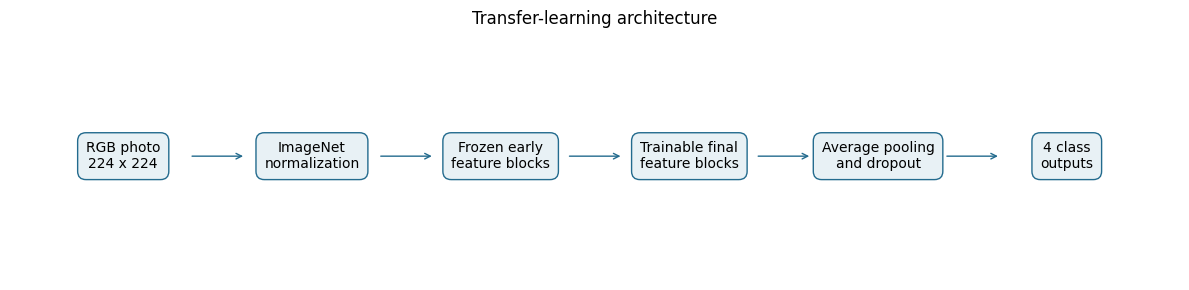

In [25]:
figure, axis = plt.subplots(figsize=(12, 3))
blocks = ["RGB photo\n224 x 224", "ImageNet\nnormalization", "Frozen early\nfeature blocks", "Trainable final\nfeature blocks", "Average pooling\nand dropout", "4 class\noutputs"]
for position, text in enumerate(blocks):
    axis.text(position, 0.5, text, ha="center", va="center", fontsize=10,
              bbox={"boxstyle": "round,pad=0.6", "facecolor": "#e8f1f5", "edgecolor": "#236b8e"})
    if position < len(blocks) - 1:
        axis.annotate("", xy=(position + 0.65, 0.5), xytext=(position + 0.35, 0.5),
                      arrowprops={"arrowstyle": "->", "color": "#236b8e"})
axis.set(xlim=(-0.6, 5.6), ylim=(0, 1), title="Transfer-learning architecture")
axis.axis("off")
figure.tight_layout()
plt.show()

### 26. Check the input and four-class output
A dummy input checks dimensions, not accuracy.

In [26]:
model.eval()
with torch.inference_mode():
    example_output = model(torch.zeros(1, 3, 224, 224, device=DEVICE))
assert tuple(example_output.shape) == (1, 4)
print("Input shape: (1, 3, 224, 224)")
print("Output shape:", tuple(example_output.shape))
print("Output class order:", CLASS_NAMES)

Input shape: (1, 3, 224, 224)
Output shape: (1, 4)
Output class order: ['cordana', 'healthy', 'pestalotiopsis', 'sigatoka']


### 27. Calculate training class weights
Minority-class training examples receive larger weights. Validation and test labels do not influence these weights.

In [27]:
training_counts = train_images.class_number.value_counts().reindex(range(4)).to_numpy()
class_weights = len(train_images) / (len(CLASS_NAMES) * training_counts)
weight_tensor = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
training_loss_function = nn.CrossEntropyLoss(weight=weight_tensor)
reporting_loss_function = nn.CrossEntropyLoss()
display(pd.DataFrame({"class": CLASS_NAMES, "training_images": training_counts,
                      "training_weight": class_weights.round(3)}))

,class,training_images,training_weight
0,cordana,113,1.387
1,healthy,63,2.488
2,pestalotiopsis,120,1.306
3,sigatoka,331,0.474


### 28. Set up Adam and early-stopping settings
The classifier learns faster than pretrained features. Reduce the learning rate when validation loss plateaus.

In [28]:
optimizer = torch.optim.Adam([
    {"params": [p for p in model.features.parameters() if p.requires_grad], "lr": 0.0001},
    {"params": model.classifier.parameters(), "lr": 0.001}
], weight_decay=0.0001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)
MAX_EPOCHS = 30
PATIENCE = 6
print("Adam optimizer; weighted cross-entropy training loss.")
print("Learning rates: features=0.0001, classifier=0.001.")
print(f"Maximum epochs: {MAX_EPOCHS}; early-stopping patience: {PATIENCE}.")

Adam optimizer; weighted cross-entropy training loss.
Learning rates: features=0.0001, classifier=0.001.
Maximum epochs: 30; early-stopping patience: 6.


### 29. Define one training epoch
Predict, calculate loss, clear gradients, backpropagate and update weights. Frozen blocks stay in evaluation mode to keep their batch-normalization statistics fixed.

In [29]:
def train_one_epoch():
    model.train()
    model.features[:-3].eval()
    total_loss, correct, total_images = 0.0, 0, 0
    for photos, labels in train_loader:
        photos, labels = photos.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        logits = model(photos)
        loss = training_loss_function(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += reporting_loss_function(logits.detach(), labels).item() * len(labels)
        correct += (logits.argmax(1) == labels).sum().item()
        total_images += len(labels)
    return total_loss / total_images, correct / total_images

print("One-epoch training function ready.")

One-epoch training function ready.


### 30. Define evaluation without learning
Disable dropout and gradients. Return loss, accuracy and probabilities in loader order.

In [30]:
def evaluate_model(image_loader):
    model.eval()
    total_loss, correct, total_images = 0.0, 0, 0
    all_probabilities = []
    with torch.inference_mode():
        for photos, labels in image_loader:
            photos, labels = photos.to(DEVICE), labels.to(DEVICE)
            logits = model(photos)
            total_loss += reporting_loss_function(logits, labels).item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            total_images += len(labels)
            all_probabilities.append(logits.softmax(1).cpu().numpy())
    return total_loss / total_images, correct / total_images, np.concatenate(all_probabilities)

print("Evaluation function ready; it never updates weights.")

Evaluation function ready; it never updates weights.


### 31. Train with early stopping
Only training and validation are used. Every printed row is an actual epoch; keep a copy of the lowest-validation-loss weights.

In [31]:
history_rows = []
best_validation_loss = float("inf")
patience_used = 0
for epoch in range(1, MAX_EPOCHS + 1):
    started = time.time()
    train_loss, train_accuracy = train_one_epoch()
    validation_loss, validation_accuracy, _ = evaluate_model(validation_loader)
    history_rows.append({"epoch": epoch, "train_loss": train_loss, "train_accuracy": train_accuracy,
                         "validation_loss": validation_loss, "validation_accuracy": validation_accuracy})
    print(f"Epoch {epoch:02d} | train acc {train_accuracy:.3f} | val acc {validation_accuracy:.3f} | "
          f"train loss {train_loss:.3f} | val loss {validation_loss:.3f} | {time.time()-started:.1f}s", flush=True)
    scheduler.step(validation_loss)
    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        best_weights = copy.deepcopy(model.state_dict())
        best_epoch = epoch
        patience_used = 0
    else:
        patience_used += 1
    if patience_used >= PATIENCE:
        print(f"Early stopping: no lower validation loss for {PATIENCE} epochs.")
        break
model.load_state_dict(best_weights)
print(f"Restored epoch {best_epoch}: lowest validation loss.")

C:\Users\Godson IT\AppData\Local\Programs\Python\Python312\Lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))
C:\Users\Godson IT\AppData\Local\Programs\Python\Python312\Lib\site-packages\PIL\JpegImagePlugin.py:880: UserWarning: Image appears to be a malformed MPO file, it will be interpreted as a base JPEG file
  warnings.warn(


Epoch 01 | train acc 0.805 | val acc 0.889 | train loss 0.585 | val loss 0.347 | 22.7s


Epoch 02 | train acc 0.962 | val acc 0.948 | train loss 0.146 | val loss 0.153 | 17.0s


Epoch 03 | train acc 0.971 | val acc 0.956 | train loss 0.094 | val loss 0.133 | 17.0s


Epoch 04 | train acc 0.984 | val acc 0.956 | train loss 0.078 | val loss 0.134 | 15.9s


...

Epoch 16 | train acc 1.000 | val acc 0.978 | train loss 0.003 | val loss 0.037 | 13.4s


Epoch 17 | train acc 0.998 | val acc 0.978 | train loss 0.004 | val loss 0.039 | 14.4s


Epoch 18 | train acc 0.998 | val acc 0.985 | train loss 0.004 | val loss 0.046 | 12.7s


Epoch 19 | train acc 0.998 | val acc 0.985 | train loss 0.006 | val loss 0.043 | 12.8s


Early stopping: no lower validation loss for 6 epochs.
Restored epoch 13: lowest validation loss.


### 32. Save the actual training history
The stopping point and selected epoch are taken from the real run.

In [32]:
history = pd.DataFrame(history_rows)
history.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
print("Actual epochs completed:", len(history))
print("Best validation-loss epoch:", best_epoch)
if len(history) < MAX_EPOCHS:
    print(f"Stopped after {PATIENCE} consecutive epochs without lower validation loss.")
else:
    print("Reached the 30-epoch limit.")
display(history.tail())

Actual epochs completed: 19
Best validation-loss epoch: 13
Stopped after 6 consecutive epochs without lower validation loss.


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy
14,15,0.007401,0.998405,0.047126,0.977778
15,16,0.003342,1.000000,0.037439,0.977778
16,17,0.004029,0.998405,0.038995,0.977778
17,18,0.003919,0.998405,0.046366,0.985185
18,19,0.005592,0.998405,0.043009,0.985185


### 33. Plot training and validation accuracy
A widening gap may suggest overfitting, but augmented training examples are harder than validation images.

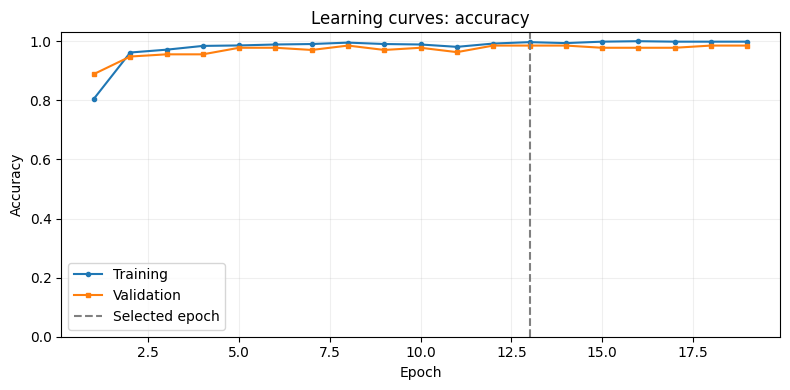

In [33]:
figure, axis = plt.subplots(figsize=(8, 4))
axis.plot(history.epoch, history.train_accuracy, "o-", label="Training", markersize=3)
axis.plot(history.epoch, history.validation_accuracy, "s-", label="Validation", markersize=3)
axis.axvline(best_epoch, linestyle="--", color="gray", label="Selected epoch")
axis.set(xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.03), title="Learning curves: accuracy")
axis.legend()
axis.grid(alpha=0.2)
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "accuracy_curve.png", dpi=160)
plt.show()

### 34. Plot training and validation loss
Lower cross-entropy is better. Validation loss selects the model; test data does not influence this choice.

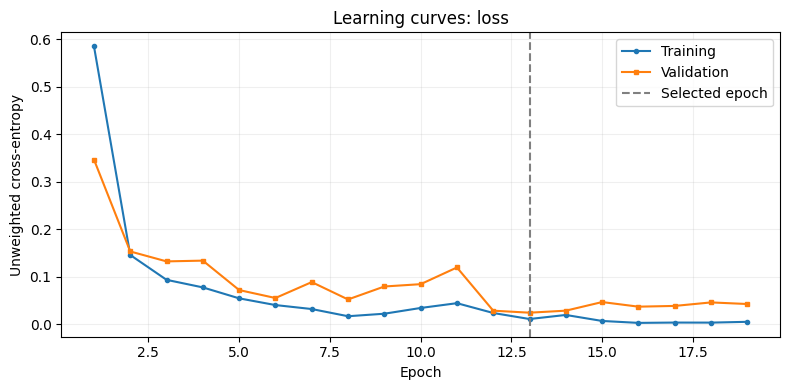

In [34]:
figure, axis = plt.subplots(figsize=(8, 4))
axis.plot(history.epoch, history.train_loss, "o-", label="Training", markersize=3)
axis.plot(history.epoch, history.validation_loss, "s-", label="Validation", markersize=3)
axis.axvline(best_epoch, linestyle="--", color="gray", label="Selected epoch")
axis.set(xlabel="Epoch", ylabel="Unweighted cross-entropy", title="Learning curves: loss")
axis.legend()
axis.grid(alpha=0.2)
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "loss_curve.png", dpi=160)
plt.show()

### 35. Explain the learning curves
The best epoch can differ from the last epoch because best weights are restored.

In [35]:
selected_epoch = history.loc[history.epoch == best_epoch].iloc[0]
last_epoch = history.iloc[-1]
print(f"Best validation loss: {selected_epoch.validation_loss:.4f} at epoch {best_epoch}.")
print(f"At that epoch: training accuracy {selected_epoch.train_accuracy:.2%}; "
      f"validation accuracy {selected_epoch.validation_accuracy:.2%}.")
print(f"Last recorded validation loss: {last_epoch.validation_loss:.4f}.")
if last_epoch.validation_loss > selected_epoch.validation_loss:
    print("Later epochs did not improve validation loss; restoring the earlier weights avoids keeping a worse fit.")
print("Increasing training accuracy with worsening validation loss suggests overfitting.")
print("Low training and validation accuracy may suggest underfitting.")

Best validation loss: 0.0248 at epoch 13.
At that epoch: training accuracy 99.68%; validation accuracy 98.52%.
Last recorded validation loss: 0.0430.
Later epochs did not improve validation loss; restoring the earlier weights avoids keeping a worse fit.
Increasing training accuracy with worsening validation loss suggests overfitting.
Low training and validation accuracy may suggest underfitting.


### 36. Compare deterministic training and validation results
Use identical non-augmented preprocessing and inference behavior for a fair fit comparison.

In [36]:
final_train_loss, final_train_accuracy, _ = evaluate_model(train_check_loader)
final_validation_loss, final_validation_accuracy, _ = evaluate_model(validation_loader)
print(f"Training:   loss={final_train_loss:.4f}, accuracy={final_train_accuracy:.2%}")
print(f"Validation: loss={final_validation_loss:.4f}, accuracy={final_validation_accuracy:.2%}")
print(f"Training minus validation accuracy: {final_train_accuracy-final_validation_accuracy:.2%}")

C:\Users\Godson IT\AppData\Local\Programs\Python\Python312\Lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))
C:\Users\Godson IT\AppData\Local\Programs\Python\Python312\Lib\site-packages\PIL\JpegImagePlugin.py:880: UserWarning: Image appears to be a malformed MPO file, it will be interpreted as a base JPEG file
  warnings.warn(


Training:   loss=0.0037, accuracy=99.84%
Validation: loss=0.0248, accuracy=98.52%
Training minus validation accuracy: 1.32%


### 37. Evaluate the untouched test split
Do not shuffle the test loader: predictions must match the test table row by row.

In [37]:
test_loader = DataLoader(LeafDataset(test_images, evaluation_transform),
                         batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loss, test_accuracy, test_probabilities = evaluate_model(test_loader)
true_numbers = test_images.class_number.to_numpy()
predicted_numbers = test_probabilities.argmax(axis=1)
assert len(test_probabilities) == len(test_images)
assert np.allclose(test_probabilities.sum(axis=1), 1, atol=1e-5)
assert np.isclose((true_numbers == predicted_numbers).mean(), test_accuracy)
print("Held-out test images:", len(test_images))
print(f"Held-out test loss: {test_loss:.4f}")
print(f"Held-out test accuracy: {test_accuracy:.2%}")

Held-out test images: 135
Held-out test loss: 0.0377
Held-out test accuracy: 97.78%


### 38. Show an evaluation dashboard
Compare split accuracies with always predicting the most common test class.

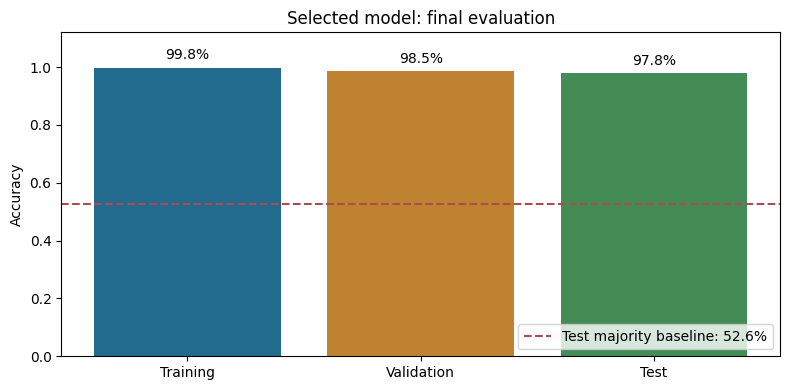

In [38]:
majority_baseline = test_images.class_name.value_counts().max() / len(test_images)
figure, axis = plt.subplots(figsize=(8, 4))
values = [final_train_accuracy, final_validation_accuracy, test_accuracy]
bars = axis.bar(["Training", "Validation", "Test"], values, color=["#236b8e", "#bf8230", "#438c56"])
axis.bar_label(bars, labels=[f"{value:.1%}" for value in values], padding=4)
axis.axhline(majority_baseline, linestyle="--", color="#aa4c52", label=f"Test majority baseline: {majority_baseline:.1%}")
axis.set(ylabel="Accuracy", ylim=(0, 1.12), title="Selected model: final evaluation")
axis.legend(loc="lower right")
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "evaluation_dashboard.png", dpi=160)
plt.show()

### 39. Plot the confusion matrix
Rows are true classes; columns are predicted classes. The diagonal counts correct predictions.

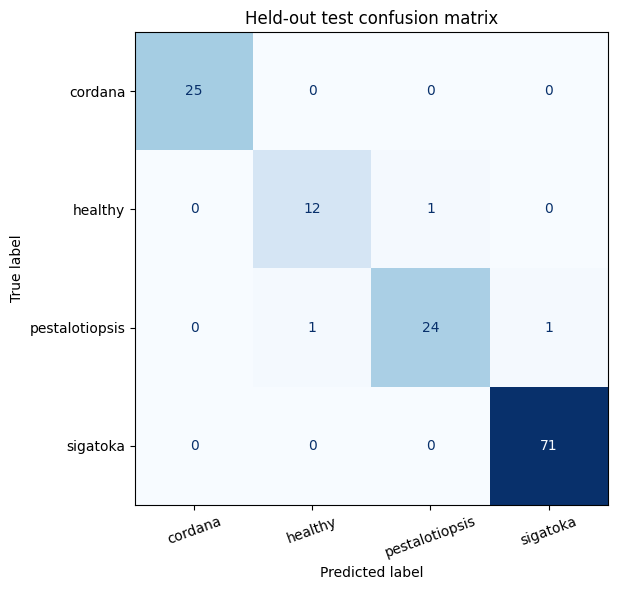

Correct predictions on the diagonal: 132 of 135


In [39]:
confusion = confusion_matrix(true_numbers, predicted_numbers, labels=range(4))
figure, axis = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(confusion, display_labels=CLASS_NAMES).plot(
    ax=axis, cmap="Blues", colorbar=False, values_format="d")
axis.set_title("Held-out test confusion matrix")
axis.tick_params(axis="x", rotation=20)
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=160)
plt.show()
print("Correct predictions on the diagonal:", int(np.trace(confusion)), "of", int(confusion.sum()))

### 40. Normalize the confusion matrix
Each row sums to one. This makes classes comparable despite different image counts.

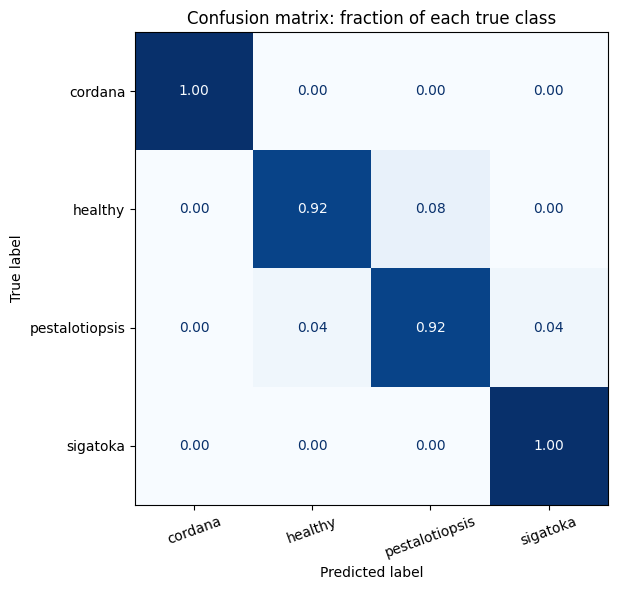

In [40]:
row_totals = confusion.sum(axis=1, keepdims=True)
normalized_confusion = confusion / np.maximum(row_totals, 1)
figure, axis = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(normalized_confusion, display_labels=CLASS_NAMES).plot(
    ax=axis, cmap="Blues", colorbar=False, values_format=".2f", im_kw={"vmin": 0, "vmax": 1})
axis.set_title("Confusion matrix: fraction of each true class")
axis.tick_params(axis="x", rotation=20)
figure.tight_layout()
plt.show()

### 41. Print precision, recall and F1
Precision measures correctness of class predictions, recall measures coverage of actual examples, and F1 balances the two. Macro F1 treats classes equally.

In [41]:
report = classification_report(true_numbers, predicted_numbers, labels=range(4),
    target_names=CLASS_NAMES, output_dict=True, zero_division=0)
print(classification_report(true_numbers, predicted_numbers, labels=range(4),
    target_names=CLASS_NAMES, digits=4, zero_division=0))
report_table = pd.DataFrame(report).T
report_table.to_csv(OUTPUT_DIR / "classification_report.csv")
print("Saved:", OUTPUT_DIR / "classification_report.csv")

                precision    recall  f1-score   support

       cordana     1.0000    1.0000    1.0000        25
       healthy     0.9231    0.9231    0.9231        13
pestalotiopsis     0.9600    0.9231    0.9412        26
      sigatoka     0.9861    1.0000    0.9930        71

      accuracy                         0.9778       135
     macro avg     0.9673    0.9615    0.9643       135
  weighted avg     0.9776    0.9778    0.9776       135

Saved: output\classification_report.csv


### 42. Visualize per-class performance
The three bars reveal differences that overall accuracy can hide.

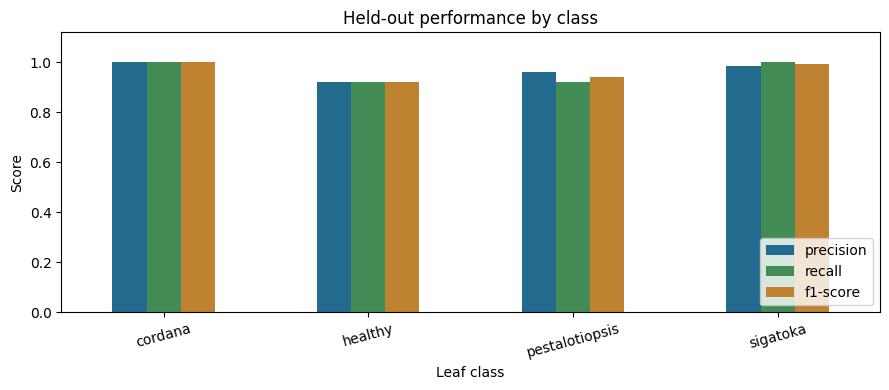

In [42]:
class_scores = pd.DataFrame({name: report[name] for name in CLASS_NAMES}).T
figure, axis = plt.subplots(figsize=(9, 4))
class_scores[["precision", "recall", "f1-score"]].plot.bar(ax=axis, color=["#236b8e", "#438c56", "#bf8230"])
axis.set(title="Held-out performance by class", xlabel="Leaf class", ylabel="Score", ylim=(0, 1.12))
axis.tick_params(axis="x", rotation=15)
axis.legend(loc="lower right")
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "class_scores.png", dpi=160)
plt.show()

### 43. Discuss mistakes and model fit
Use the numerical gap and curves together. A ten-percentage-point gap is a descriptive guide, not a formal statistical test.

In [43]:
mistakes = confusion.copy()
np.fill_diagonal(mistakes, 0)
number_wrong = int(mistakes.sum())
print(f"Misclassified test images: {number_wrong} of {len(test_images)}.")
if number_wrong:
    true_class, guessed_class = np.unravel_index(mistakes.argmax(), mistakes.shape)
    print(f"Most common error: {CLASS_NAMES[true_class]} -> {CLASS_NAMES[guessed_class]} "
          f"({mistakes[true_class, guessed_class]} images).")
weakest_class = min(CLASS_NAMES, key=lambda name: report[name]["recall"])
print(f"Lowest recall: {weakest_class} ({report[weakest_class]['recall']:.2%}).")
fit_gap = final_train_accuracy - final_validation_accuracy
if fit_gap > 0.10:
    print("The training-validation gap suggests overfitting; inspect the loss curves as well.")
elif final_train_accuracy < 0.65 and final_validation_accuracy < 0.65:
    print("Both accuracies are low, suggesting underfitting or difficult data.")
else:
    print("No large accuracy gap or obvious underfitting appears; inspect the curves for subtler signs.")

Misclassified test images: 3 of 135.
Most common error: healthy -> pestalotiopsis (1 images).
Lowest recall: healthy (92.31%).
No large accuracy gap or obvious underfitting appears; inspect the curves for subtler signs.


### 44. Conclude and discuss limitations
An image-level split cannot guarantee independence of plants or capture sessions without source metadata.

In [44]:
print(f"Conclusion: test accuracy={test_accuracy:.2%}; macro F1={report['macro avg']['f1-score']:.4f}.")
print(f"Always guessing the largest test class would give {majority_baseline:.2%} accuracy.")
print("Exact duplicates were removed; plant/session metadata was unavailable for a grouped split.")
print("Lighting, background, overlapping symptoms and small class sizes may contribute to mistakes.")
print("Inspect the error photos before attributing a specific cause.")
print("Future work: collect diverse minority-class photos and validate independently on new farms.")
print("Model changes based on these test errors would require a new untouched test set.")

Conclusion: test accuracy=97.78%; macro F1=0.9643.
Always guessing the largest test class would give 52.59% accuracy.
Exact duplicates were removed; plant/session metadata was unavailable for a grouped split.
Lighting, background, overlapping symptoms and small class sizes may contribute to mistakes.
Inspect the error photos before attributing a specific cause.
Future work: collect diverse minority-class photos and validate independently on new farms.
Model changes based on these test errors would require a new untouched test set.


### 45. Display true and predicted labels
Show up to six mistakes first, then correct examples. Red titles identify errors. The score is an uncalibrated softmax probability.

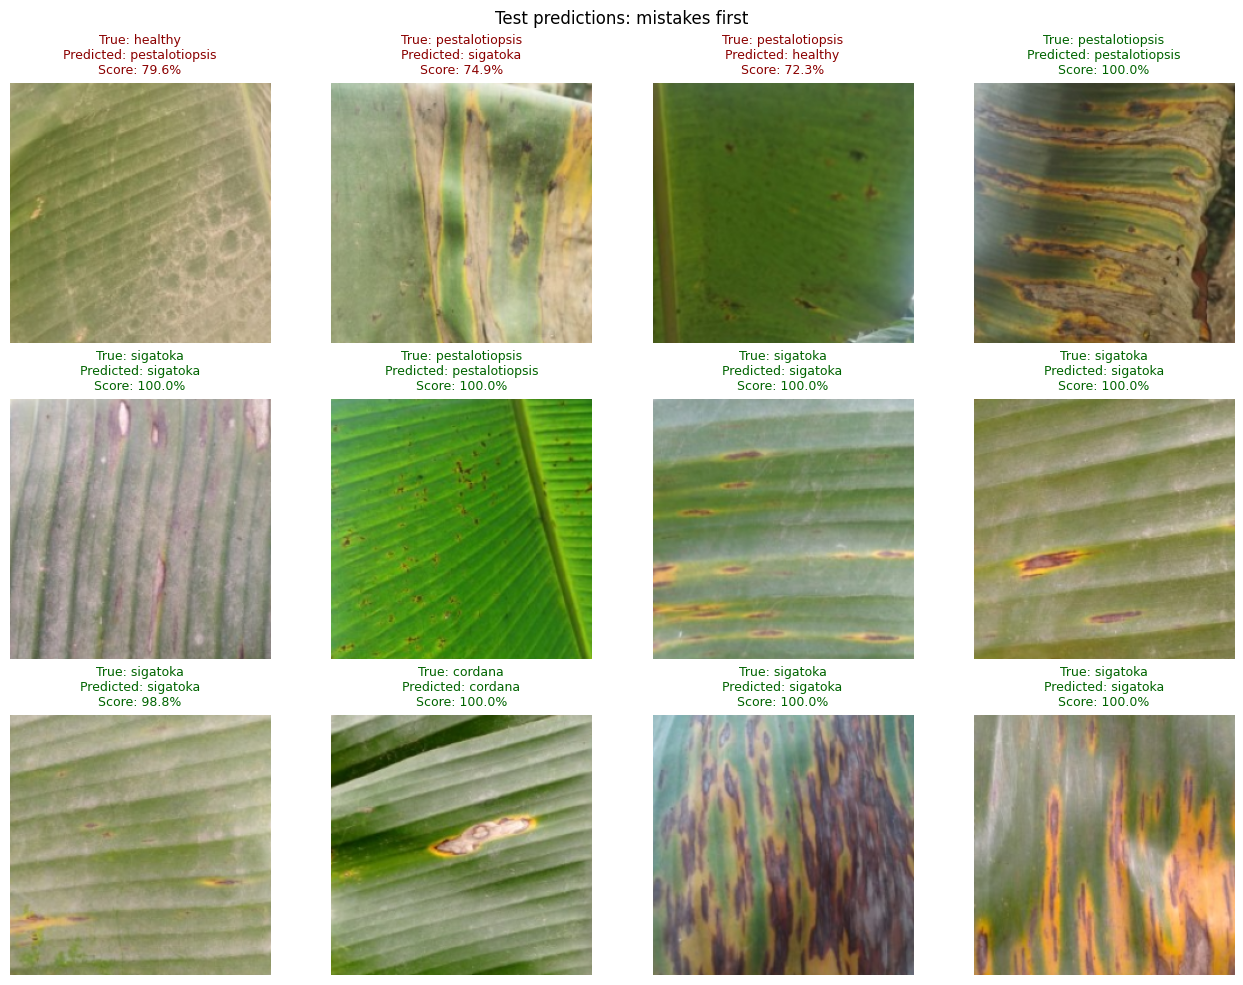

In [45]:
wrong_indices = np.flatnonzero(true_numbers != predicted_numbers)
right_indices = np.flatnonzero(true_numbers == predicted_numbers)
preview_indices = np.concatenate([wrong_indices[:6], right_indices])[:12]
figure, axes = plt.subplots(3, 4, figsize=(13, 10))
for axis in axes.flat:
    axis.axis("off")
for axis, index in zip(axes.flat, preview_indices):
    with Image.open(test_images.iloc[index].image_path) as image:
        axis.imshow(resize_and_crop(image.convert("RGB")))
    true_name, predicted_name = CLASS_NAMES[true_numbers[index]], CLASS_NAMES[predicted_numbers[index]]
    axis.set_title(f"True: {true_name}\nPredicted: {predicted_name}\nScore: {test_probabilities[index].max():.1%}",
                   fontsize=9, color="darkgreen" if true_name == predicted_name else "darkred")
figure.suptitle("Test predictions: mistakes first")
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "test_predictions.png", dpi=160)
plt.show()

### 46. Save the prediction CSV
The required identifier, true class and predicted class are included, plus probabilities for inspection.

In [46]:
predictions = test_images[["image_id", "class_name"]].rename(columns={"class_name": "true_class"}).copy()
predictions["predicted_class"] = [CLASS_NAMES[number] for number in predicted_numbers]
predictions["confidence"] = test_probabilities.max(axis=1)
for number, class_name in enumerate(CLASS_NAMES):
    predictions[f"probability_{class_name}"] = test_probabilities[:, number]
prediction_file = OUTPUT_DIR / "banana_leaf_predictions.csv"
predictions.to_csv(prediction_file, index=False)
print("Saved predictions:", prediction_file.resolve())
print("Rows:", len(predictions))
display(predictions.head())

Saved predictions: F:\janv\output\banana_leaf_predictions.csv
Rows: 135


,image_id,true_class,predicted_class,confidence,probability_cordana,probability_healthy,probability_pestalotiopsis,probability_sigatoka
0,pestalotiopsis/135.jpeg,pestalotiopsis,pestalotiopsis,0.999926,9.227668e-12,8.595913e-13,9.999262e-01,0.000074
1,sigatoka/283.jpeg,sigatoka,sigatoka,0.999539,1.640357e-04,2.770764e-04,2.029400e-05,0.999539
2,pestalotiopsis/70.jpeg,pestalotiopsis,pestalotiopsis,0.999995,2.179063e-08,1.632573e-07,9.999952e-01,0.000004
3,sigatoka/307.jpeg,sigatoka,sigatoka,1.000000,1.436829e-07,2.441418e-09,3.194828e-07,1.000000
4,sigatoka/259.jpeg,sigatoka,sigatoka,0.999824,1.762204e-04,4.369269e-10,3.382141e-07,0.999824


### 47. Save the trained model
Store the weights, architecture, class order and preprocessing settings in a PyTorch checkpoint.

In [47]:
model_file = OUTPUT_DIR / "banana_leaf_disease_model.pt"
checkpoint = {"architecture": "mobilenet_v3_small", "class_names": CLASS_NAMES,
    "model_state": {name: value.detach().cpu() for name, value in model.state_dict().items()},
    "resize_shorter_side": 256, "crop_size": 224, "mean": IMAGE_MEAN, "std": IMAGE_STD,
    "best_epoch": best_epoch, "test_loss": float(test_loss), "test_accuracy": float(test_accuracy)}
torch.save(checkpoint, model_file)
print("Saved trained model:", model_file.resolve())
print(f"Model size: {model_file.stat().st_size / 1024**2:.2f} MB")

Saved trained model: F:\janv\output\banana_leaf_disease_model.pt
Model size: 5.93 MB


### 48. Reload the saved model
Build the architecture without pretrained weights, then load the trained checkpoint. This avoids another download.

In [48]:
saved_checkpoint = torch.load(model_file, map_location="cpu", weights_only=True)
saved_model = models.mobilenet_v3_small(weights=None)
saved_model.classifier[-1] = nn.Linear(saved_model.classifier[-1].in_features, 4)
saved_model.load_state_dict(saved_checkpoint["model_state"])
saved_model.eval()
saved_transform = transforms.Compose([
    transforms.Resize(saved_checkpoint["resize_shorter_side"]),
    transforms.CenterCrop(saved_checkpoint["crop_size"]), transforms.ToTensor(),
    transforms.Normalize(saved_checkpoint["mean"], saved_checkpoint["std"])
])
print("Reloaded. Classes:", saved_checkpoint["class_names"])

Reloaded. Classes: ['cordana', 'healthy', 'pestalotiopsis', 'sigatoka']


### 49. Verify the saved files
Check that the reloaded model agrees with earlier predictions and that the CSV preserves image order.

In [49]:
verification_photos = []
for image_path in test_images.image_path.iloc[:3]:
    with Image.open(image_path) as image:
        verification_photos.append(saved_transform(image.convert("RGB")))
with torch.inference_mode():
    reloaded_probabilities = saved_model(torch.stack(verification_photos)).softmax(1).numpy()
np.testing.assert_allclose(reloaded_probabilities, test_probabilities[:3], rtol=1e-4, atol=1e-5)
saved_predictions = pd.read_csv(prediction_file)
assert saved_predictions.image_id.tolist() == test_images.image_id.tolist()
assert saved_predictions.true_class.tolist() == test_images.class_name.tolist()
assert len(saved_predictions) == len(test_images)
print("Passed: saved model reproduces predictions.")
print("Passed: CSV identifiers, labels and row count match.")

Passed: saved model reproduces predictions.
Passed: CSV identifiers, labels and row count match.


### 50. Define prediction for one photo
Use the saved preprocessing and class order. Return the predicted name and all four probabilities.

In [50]:
def predict_leaf_photo(photo):
    input_tensor = saved_transform(photo.convert("RGB")).unsqueeze(0)
    with torch.inference_mode():
        probabilities = saved_model(input_tensor).softmax(1).numpy()[0]
    predicted_number = int(probabilities.argmax())
    return saved_checkpoint["class_names"][predicted_number], probabilities

print("Single-photo prediction ready using the saved model.")

Single-photo prediction ready using the saved model.


### 51. Define the image and probability chart
Display the photo beside all four class scores, so alternative predictions remain visible.

In [51]:
def show_leaf_prediction(photo, title="Your leaf photo"):
    predicted_class, probabilities = predict_leaf_photo(photo)
    figure, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(photo.convert("RGB"))
    axes[0].set_title(title)
    axes[0].axis("off")
    bars = axes[1].barh(saved_checkpoint["class_names"], probabilities, color="#438c56")
    axes[1].bar_label(bars, labels=[f"{value:.1%}" for value in probabilities], padding=3)
    axes[1].set(xlim=(0, 1.15), xlabel="Model probability", title=f"Prediction: {predicted_class}")
    figure.tight_layout()
    plt.show()
    print(f"Predicted class: {predicted_class}; top score: {probabilities.max():.1%}")
    return predicted_class, probabilities

print("Photo and probability-chart display ready.")

Photo and probability-chart display ready.


### 52. Demonstrate the saved-model tester
Use one final test image to demonstrate inference; this does not update the model.

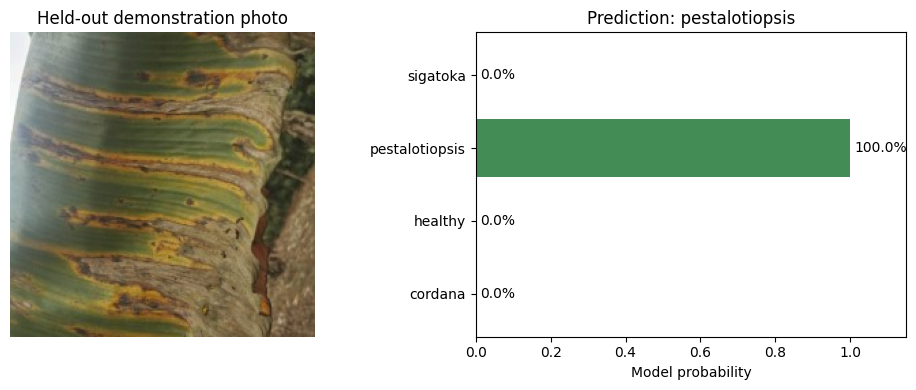

Predicted class: pestalotiopsis; top score: 100.0%
True class: pestalotiopsis
Image identifier: pestalotiopsis/135.jpeg


In [52]:
demo_row = test_images.iloc[0]
with Image.open(demo_row.image_path) as image:
    demo_photo = image.convert("RGB")
demo_prediction, demo_scores = show_leaf_prediction(demo_photo, "Held-out demonstration photo")
print("True class:", demo_row.class_name)
print("Image identifier:", demo_row.image_id)

### 53. Define the upload handler
Read the selected file bytes, decode the photo and run the saved model. Invalid image files receive a readable message.

In [53]:
import ipywidgets as widgets
upload_result = widgets.Output()

def handle_leaf_upload(change):
    with upload_result:
        upload_result.clear_output(wait=True)
        if not upload_button.value:
            return
        files = upload_button.value
        uploaded_file = next(iter(files.values())) if isinstance(files, dict) else files[0]
        try:
            with Image.open(io.BytesIO(bytes(uploaded_file["content"]))) as image:
                photo = image.convert("RGB")
            show_leaf_prediction(photo, uploaded_file.get("name", "Uploaded photo"))
        except (OSError, ValueError) as error:
            print("Choose a readable JPG, PNG or WebP leaf photo.", str(error))

print("Upload handler ready.")

Upload handler ready.


### 54. Upload your own leaf photo
Click the button, choose a photo and wait for the chart. Use a live notebook kernel; a static export cannot run predictions. If the editor shows a widget placeholder, use JupyterLab with widgets enabled.

In [54]:
upload_button = widgets.FileUpload(accept="image/*", multiple=False, description="Upload leaf photo")
upload_button.observe(handle_leaf_upload, names="value")
display(widgets.VBox([widgets.HTML("<b>Test your own banana leaf photo</b>"), upload_button, upload_result]))
print("Ready: upload a photo to test the saved model. Deployment has not started.")

Ready: upload a photo to test the saved model. Deployment has not started.


### 55. Check image-file inference
Read a real image as bytes, just like the upload handler, and verify the prediction agrees with the model evaluation.

In [55]:
demo_bytes = Path(demo_row.image_path).read_bytes()
with Image.open(io.BytesIO(demo_bytes)) as image:
    byte_prediction, byte_scores = predict_leaf_photo(image.convert("RGB"))
assert byte_prediction == demo_prediction
np.testing.assert_allclose(byte_scores, test_probabilities[0], rtol=1e-4, atol=1e-5)
print("Passed: image bytes decode and the saved model reproduces the test prediction.")
print("You can now use the upload button above with your own photo.")

Passed: image bytes decode and the saved model reproduces the test prediction.
You can now use the upload button above with your own photo.


### 56. List the completed deliverables
Keep the model and CSV locally even though the brief requests only the notebook upload.

In [56]:
metrics = {"test_loss": float(test_loss), "test_accuracy": float(test_accuracy),
    "macro_f1": float(report["macro avg"]["f1-score"]), "best_epoch": int(best_epoch),
    "actual_epochs": len(history), "unique_images": len(images), "training_images": len(train_images),
    "validation_images": len(validation_images), "test_images": len(test_images)}
with (OUTPUT_DIR / "evaluation_metrics.json").open("w") as file:
    json.dump(metrics, file, indent=2)
for file_path in [model_file, prediction_file, OUTPUT_DIR / "evaluation_metrics.json"]:
    assert file_path.exists() and file_path.stat().st_size > 0
    print("Ready:", file_path.resolve())
print("Review the outputs and test your photos. Deployment awaits your go-ahead.")

Ready: F:\janv\output\banana_leaf_disease_model.pt
Ready: F:\janv\output\banana_leaf_predictions.csv
Ready: F:\janv\output\evaluation_metrics.json
Review the outputs and test your photos. Deployment awaits your go-ahead.
